# 01 · EDA — Ukrainian grade-5 mathematics dataset (UCU AI 2026, LLM homework)

**Scope of this notebook:** exploratory data analysis, dataset-quality checks and creation of a *fixed* validation split.
It does **not** load any language model, run inference, solve problems, generate solutions, or inspect individual test problems.

**Conventions**
- Everything is computed from the data; no result is hard-coded.
- Raw records are never modified or deleted. Issues are *reported*, not fixed.
- Regular expressions are used only to inspect *formats / templates*, never to solve or predict answers.
- Test data: only schema and aggregate integrity checks (no reading of individual statements).

**Sections:** 1 Setup · 2 Overview & integrity · 3 Skills · 4 Answer formats · 5 Statements · 6 Steps · 7 Hints · 8 Typical errors · 9 Duplicates & templates · 10 Fixed validation split · 11 Summary & planning

## 1. Setup and data loading

In [1]:
import os, re, ast, json, math, textwrap, unicodedata, warnings
from collections import Counter
from fractions import Fraction
from decimal import Decimal
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ---- configuration -------------------------------------------------------
LOCAL_DATA_DIR = None   # optional: e.g. "./data" when running outside Kaggle
LOCAL_OUT_DIR = None    # optional: output dir override
# --------------------------------------------------------------------------

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 60)

def find_data_dir(local=None):
    # Locate the folder containing train.csv and test.csv.
    if local:
        p = Path(local)
        assert (p / "train.csv").exists(), f"train.csv not found in {p}"
        return p
    root = Path("/kaggle/input")
    if root.exists():
        for f in sorted(root.rglob("train.csv")):
            if (f.parent / "test.csv").exists():
                return f.parent
    for p in (Path("."), Path("data")):
        if (p / "train.csv").exists():
            return p
    raise FileNotFoundError("Dataset not found. Set LOCAL_DATA_DIR.")

DATA_DIR = find_data_dir(LOCAL_DATA_DIR)
OUT_DIR = Path(LOCAL_OUT_DIR) if LOCAL_OUT_DIR else (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = OUT_DIR / "eda_tables"
TABLE_DIR.mkdir(exist_ok=True)
assert DATA_DIR.resolve() != OUT_DIR.resolve(), "Output dir must differ from data dir (originals are never overwritten)."
print("Data dir  :", DATA_DIR)
print("Output dir:", OUT_DIR)

def save_table(df, name, index=True):
    # Save a summary table for later notebooks.
    df.to_csv(TABLE_DIR / f"{name}.csv", index=index, encoding="utf-8")

def natural_key(s):
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", str(s))]

def normalize_text(s):
    # Unicode (NFKC) + case folding + whitespace collapsing. Used only for duplicate detection.
    s = unicodedata.normalize("NFKC", str(s)).casefold()
    return re.sub(r"\s+", " ", s).strip()

Data dir  : /kaggle/input/competitions/ukrainian-school-math-slm-hw4-ucu-ai-2026
Output dir: /kaggle/working


In [2]:
# Load everything as strings: ids/answers keep their exact original representation.
# Only truly empty cells become NaN ("NA", "null", ... stay as text).
def read_csv_str(name):
    return pd.read_csv(DATA_DIR / name, dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8")

train = read_csv_str("train.csv")
test = read_csv_str("test.csv")
sample_sub = read_csv_str("sample_submission.csv")

for name, df in [("train", train), ("test", test), ("sample_submission", sample_sub)]:
    print(f"{name:18s} shape={df.shape}  columns={list(df.columns)}")

train              shape=(1526, 8)  columns=['id', 'skill', 'skill_title', 'statement', 'answer', 'steps', 'hints', 'typical_errors']
test               shape=(3561, 4)  columns=['id', 'skill', 'skill_title', 'statement']
sample_submission  shape=(3561, 2)  columns=['id', 'answer']


## 2. Dataset overview and integrity checks
Issues are only **reported** here — no record is changed or removed.

,dataset,column,dtype,missing,whitespace_only,pct_missing_or_blank
0,train,id,object,0,0,0.0
1,train,skill,object,0,0,0.0
2,train,skill_title,object,0,0,0.0
3,train,statement,object,0,0,0.0
4,train,answer,object,0,0,0.0
5,train,steps,object,0,0,0.0
6,train,hints,object,0,0,0.0
7,train,typical_errors,object,0,0,0.0
8,test,id,object,0,0,0.0
9,test,skill,object,0,0,0.0


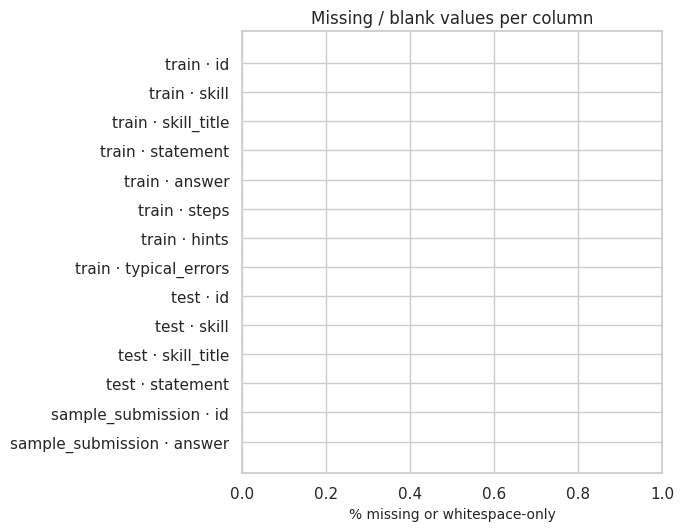

In [3]:
def missing_report(df, name):
    rows = []
    for c in df.columns:
        miss = int(df[c].isna().sum())
        ws = int((df[c].notna() & df[c].fillna("").str.strip().eq("")).sum())
        rows.append(dict(dataset=name, column=c, dtype=str(df[c].dtype), missing=miss, whitespace_only=ws,
                         pct_missing_or_blank=round(100 * (miss + ws) / len(df), 2)))
    return pd.DataFrame(rows)

miss_df = pd.concat([missing_report(train, "train"), missing_report(test, "test"), missing_report(sample_sub, "sample_submission")],
                    ignore_index=True)
display(miss_df)
save_table(miss_df, "missing_values", index=False)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(miss_df) + 1))
labels = miss_df["dataset"] + " · " + miss_df["column"]
ax.barh(labels, miss_df["pct_missing_or_blank"], color="#c0504d")
ax.invert_yaxis()
ax.set_xlabel("% missing or whitespace-only")
ax.set_title("Missing / blank values per column")
ax.set_xlim(0, max(1, miss_df["pct_missing_or_blank"].max() * 1.1))
plt.tight_layout(); plt.show()

In [4]:
# ---- identifiers, duplicates, overlap, skill/title consistency -------------
train_ids, test_ids, sub_ids = set(train["id"].dropna()), set(test["id"].dropna()), set(sample_sub["id"].dropna())
t_norm = train["statement"].fillna("").map(normalize_text)

skill_titles = train.groupby("skill")["skill_title"].nunique()
title_skills = train.groupby("skill_title")["skill"].nunique()
tt = test.groupby("skill")["skill_title"].nunique()
train_map = train.drop_duplicates("skill").set_index("skill")["skill_title"]
test_map = test.drop_duplicates("skill").set_index("skill")["skill_title"]
common_sk = train_map.index.intersection(test_map.index)

integrity = pd.Series({
    "train rows": len(train), "test rows": len(test), "sample_submission rows": len(sample_sub),
    "train duplicated ids": int(train["id"].duplicated().sum()),
    "test duplicated ids": int(test["id"].duplicated().sum()),
    "sample_submission duplicated ids": int(sample_sub["id"].duplicated().sum()),
    "train ∩ test ids": len(train_ids & test_ids),
    "test ids == sample_submission ids (as sets)": test_ids == sub_ids,
    "test ids == sample_submission ids (same order)": bool(test["id"].reset_index(drop=True).equals(sample_sub["id"].reset_index(drop=True))),
    "train exact duplicate statements (rows beyond first)": int(train["statement"].duplicated().sum()),
    "train normalized duplicate statements (rows beyond first)": int(t_norm.duplicated().sum()),
    "train unique skills": train["skill"].nunique(),
    "test unique skills": test["skill"].nunique(),
    "same skill set in train and test": set(train["skill"]) == set(test["skill"]),
    "skills with >1 title (train)": int((skill_titles > 1).sum()),
    "titles shared by >1 skill (train)": int((title_skills > 1).sum()),
    "skill->title mismatches train vs test": int((train_map.loc[common_sk] != test_map.loc[common_sk]).sum()),
}, name="value").to_frame()
display(integrity)
save_table(integrity, "integrity_checks")
print("Example ids:", train["id"].head(3).tolist(), "(loaded as strings)")

,value
train rows,1526
test rows,3561
sample_submission rows,3561
train duplicated ids,0
test duplicated ids,0
sample_submission duplicated ids,0
train ∩ test ids,0
test ids == sample_submission ids (as sets),True
test ids == sample_submission ids (same order),True
train exact duplicate statements (rows beyond first),0


Example ids: ['02d631', '4c2249', '911fcb'] (loaded as strings)


## 3. Skill distribution (training data)

,skill_title,n_train,pct_train
skill,,,
N-DIVTEST,Ознаки подільності,60,3.93
N-MUL-MULTI,Множення багатоцифрового числа на одноцифрове й двоцифрове,60,3.93
D-SUB,Віднімання десяткових дробів,60,3.93
N-ROUND,Округлення натуральних чисел,60,3.93
N-ADD-MULTI,Додавання багатоцифрових чисел стовпчиком,60,3.93
WORD-2,Текстові задачі у дві дії,60,3.93
D-MUL10,"Множення й ділення десяткових на 10, 100, 1000",60,3.93
AVG,Середнє арифметичне,60,3.93
N-SUB-MULTI,Віднімання багатоцифрових чисел стовпчиком,60,3.93


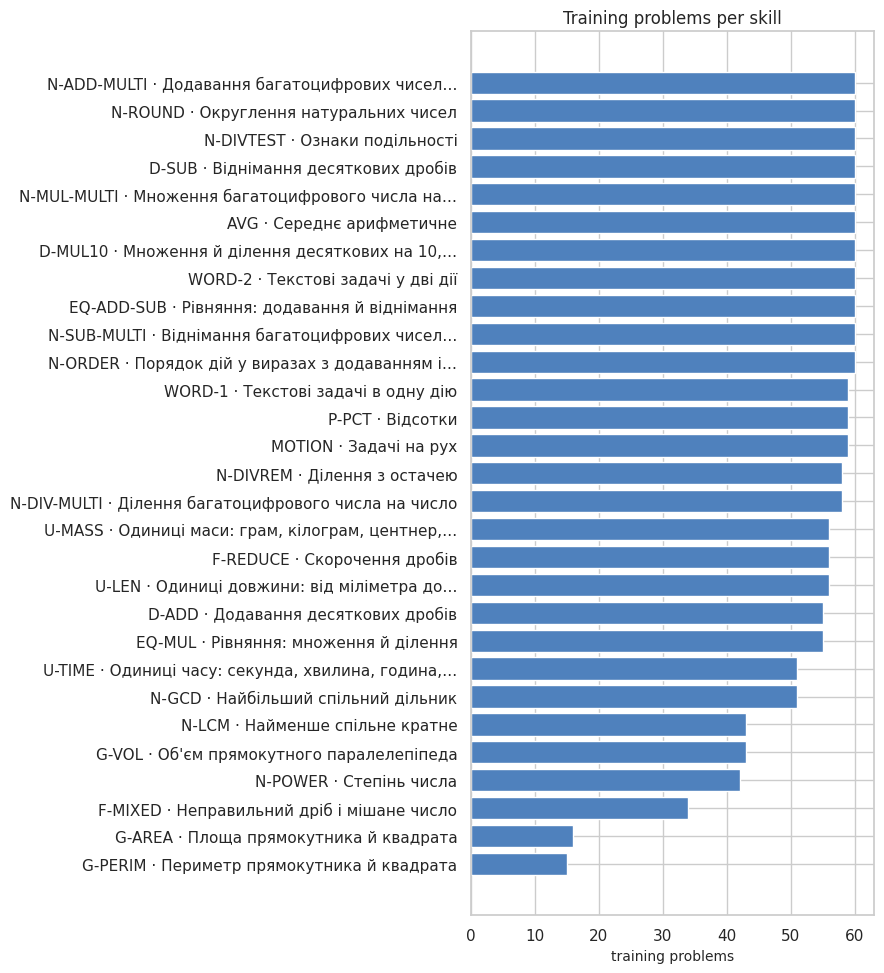

Per-skill counts: {'min': 15.0, 'max': 60.0, 'median': 58.0, 'mean': 52.62}
Most represented : N-DIVTEST · Ознаки подільності 60
Least represented: G-PERIM · Периметр прямокутника й квадрата 15
Expected validation size of the smallest skill at 20%: 3.0


In [5]:
skill_title_map = train.drop_duplicates("skill").set_index("skill")["skill_title"].to_dict()
def skill_label(code, width=40):
    return f"{code} · {textwrap.shorten(str(skill_title_map.get(code, '')), width, placeholder='…')}"

skill_counts = train["skill"].value_counts()
skill_tbl = pd.DataFrame({"skill_title": [skill_title_map.get(s, "") for s in skill_counts.index],
                          "n_train": skill_counts.values,
                          "pct_train": (100 * skill_counts / len(train)).round(2).values}, index=skill_counts.index)
skill_tbl.index.name = "skill"
display(skill_tbl)
save_table(skill_tbl, "skill_distribution")

fig, ax = plt.subplots(figsize=(9, 0.3 * len(skill_tbl) + 1.2))
order = skill_tbl.sort_values("n_train")
ax.barh([skill_label(s) for s in order.index], order["n_train"], color="#4f81bd")
ax.set_xlabel("training problems"); ax.set_title("Training problems per skill")
plt.tight_layout(); plt.show()

skill_stats = skill_counts.agg(["min", "max", "median", "mean"]).round(2)
print("Per-skill counts:", skill_stats.to_dict())
print("Most represented :", skill_label(skill_counts.idxmax()), skill_counts.max())
print("Least represented:", skill_label(skill_counts.idxmin()), skill_counts.min())
print("Expected validation size of the smallest skill at 20%:", round(0.2 * skill_counts.min(), 1))

In [6]:
# Test: schema / aggregate checks ONLY (no individual statements are displayed or analysed).
test_skill_pct = 100 * test["skill"].value_counts(normalize=True)
train_skill_pct = 100 * train["skill"].value_counts(normalize=True)
cmp = pd.DataFrame({"train_pct": train_skill_pct, "test_pct": test_skill_pct}).fillna(0)
cmp["abs_diff"] = (cmp["train_pct"] - cmp["test_pct"]).abs()
print("Max |train% - test%| over skills:", round(cmp["abs_diff"].max(), 3))
print("Test blank statements:", int(test["statement"].isna().sum() + test["statement"].fillna("x").str.strip().eq("").sum()))

Max |train% - test%| over skills: 0.047
Test blank statements: 0


**Implications (to be checked against the numbers above).**
- *Stratified validation:* the smallest skill determines how few validation items a skill gets at 20%; per-skill accuracy on the validation set will be noisy for small skills, so report aggregate accuracy as the primary metric and per-skill numbers as indicative only.
- *Few-shot selection:* every skill has enough training examples to draw several demonstrations from the **training** part of the split only.
- *Fine-tuning:* if the distribution is imbalanced, consider whether to keep the natural distribution (matches the stratified test set) or to rebalance; the test set is stratified by skill, so the natural skill mix is the relevant target distribution.

## 4. Answer format analysis
Answers are classified by **string pattern only** (integer / decimal / fraction / other). Numerical equivalence is not used to merge formats:
under exact-match scoring `0.5`, `1/2` and `0.50` are three different answers, so a model must also reproduce the canonical *representation*.

In [7]:
RE_INT, RE_DEC, RE_FRAC = re.compile(r"-?\d+"), re.compile(r"-?\d+\.\d+"), re.compile(r"-?\d+/\d+")

def classify_answer(a):
    # Format inspection only (never used to compute an answer).
    if pd.isna(a): return "Missing"
    if RE_INT.fullmatch(a): return "Integer"
    if RE_DEC.fullmatch(a): return "Decimal"
    if RE_FRAC.fullmatch(a): return "Fraction"
    return "Other"

def answer_issues(a):
    # List of canonical-format problems (empty list = looks canonical).
    t = classify_answer(a)
    if t == "Missing": return ["missing"]
    issues = []
    if a != a.strip(): issues.append("surrounding_whitespace")
    if t == "Integer":
        if re.match(r"-?0\d", a): issues.append("integer_leading_zero")
        if a.startswith("-0"): issues.append("negative_zero")
    elif t == "Decimal":
        if re.match(r"-?0\d", a): issues.append("decimal_leading_zero")
        if a.endswith("0"): issues.append("decimal_trailing_zero")
    elif t == "Fraction":
        n, d = (int(x) for x in a.lstrip("-").split("/"))
        if d == 0: issues.append("zero_denominator")
        else:
            if math.gcd(n, d) != 1: issues.append("not_lowest_terms")
            if d == 1: issues.append("denominator_one")
    else:
        issues.append("decimal_comma" if re.fullmatch(r"-?\d+,\d+", a.strip()) else "unexpected_format")
    return issues

def exact_value(a):
    # Exact numeric value (Fraction) for inspection of sign/size only; original string is never replaced.
    try: return Fraction(a.strip())
    except (ValueError, ZeroDivisionError, AttributeError): return None

ans = train["answer"]
train_ans = pd.DataFrame({"id": train["id"], "skill": train["skill"], "answer": ans})
train_ans["a_type"] = ans.map(classify_answer)
train_ans["issues"] = ans.map(answer_issues)
train_ans["value"] = ans.map(exact_value)

type_counts = train_ans["a_type"].value_counts()
type_tbl = pd.DataFrame({"count": type_counts, "pct": (100 * type_counts / len(train_ans)).round(2)})
display(type_tbl)
save_table(type_tbl, "answer_type_distribution")

issue_counts = Counter(i for lst in train_ans["issues"] for i in lst)
print("Potentially non-canonical / malformed answers (count by issue):", dict(issue_counts) or "none detected")
bad = train_ans[train_ans["issues"].map(len) > 0]
if len(bad):
    display(bad[["id", "skill", "answer", "a_type", "issues"]].head(8))

,count,pct
a_type,,
Integer,1366,89.52
Decimal,136,8.91
Fraction,24,1.57


Potentially non-canonical / malformed answers (count by issue): none detected


a_type,Decimal,Fraction,Integer
skill,,,
AVG,0.0,0.0,100.0
D-ADD,80.0,0.0,20.0
D-MUL10,53.3,13.3,33.3
D-SUB,100.0,0.0,0.0
EQ-ADD-SUB,0.0,0.0,100.0
EQ-MUL,0.0,0.0,100.0
F-MIXED,0.0,47.1,52.9
F-REDUCE,0.0,0.0,100.0
G-AREA,0.0,0.0,100.0


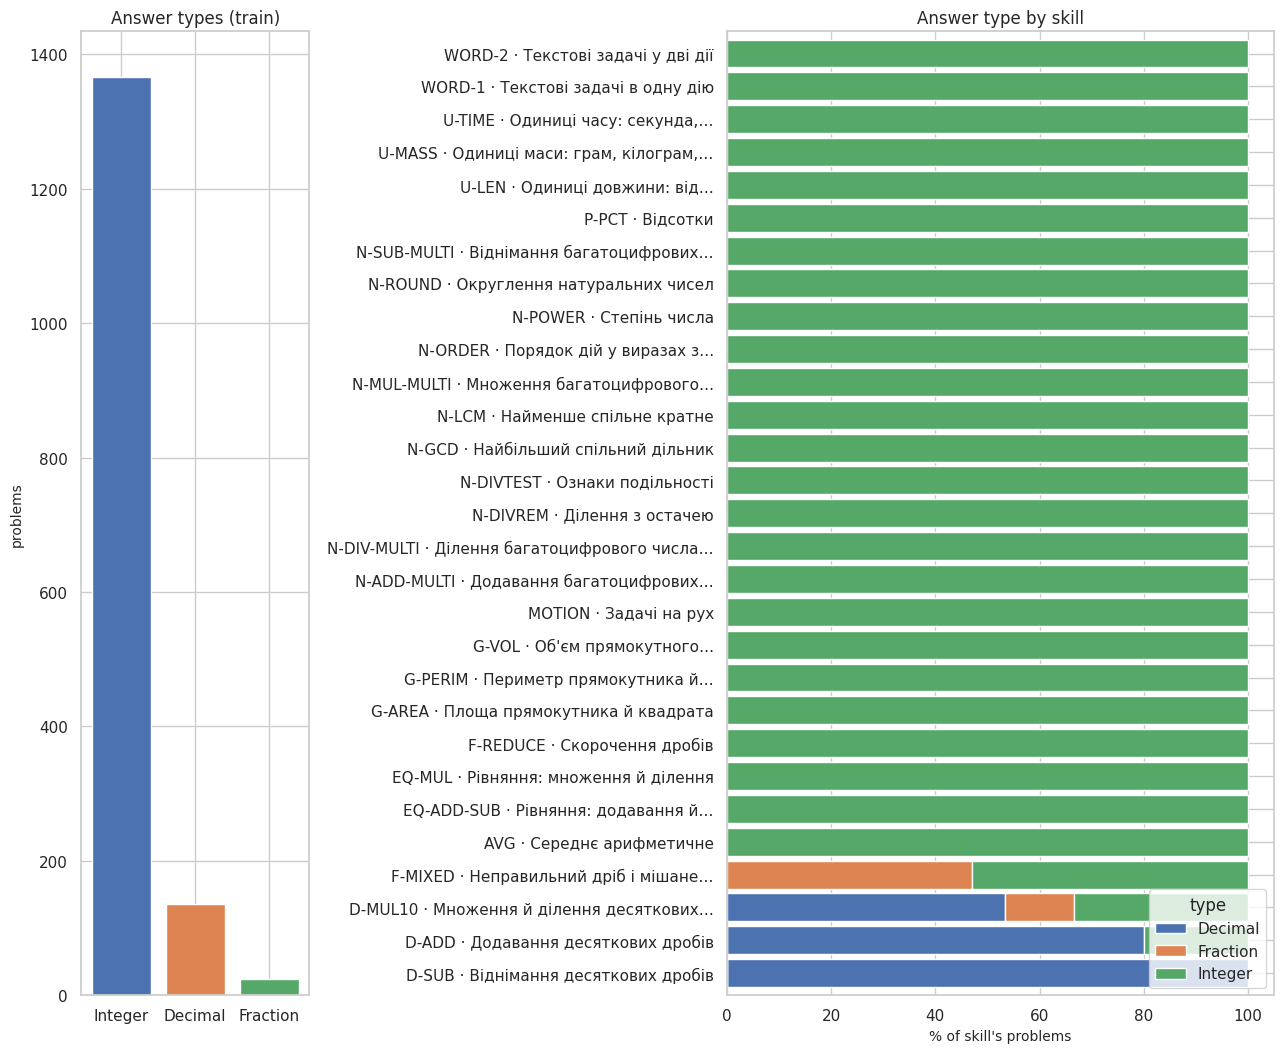

In [8]:
# ---- type per skill -------------------------------------------------------
ct = pd.crosstab(train_ans["skill"], train_ans["a_type"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
display(ct_pct.round(1).loc[sorted(ct_pct.index, key=natural_key)])
save_table(ct, "answer_type_by_skill_counts")

fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * len(ct) + 2), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].bar(type_tbl.index, type_tbl["count"], color=sns.color_palette("deep")[: len(type_tbl)])
axes[0].set_title("Answer types (train)"); axes[0].set_ylabel("problems")
sort_col = "Integer" if "Integer" in ct_pct else ct_pct.columns[0]
ct_plot = ct_pct.sort_values(sort_col)
ct_plot.index = [skill_label(s, 30) for s in ct_plot.index]
ct_plot.plot(kind="barh", stacked=True, ax=axes[1], color=sns.color_palette("deep"), width=0.85)
axes[1].set_xlabel("% of skill's problems"); axes[1].set_title("Answer type by skill"); axes[1].legend(title="type", loc="lower right")
plt.tight_layout(); plt.show()

,integer digits,decimal places,numerator,denominator
count,1366.00,136.00,24.00,24.00
mean,2.58,1.94,71.04,96.75
std,1.14,1.14,124.61,237.40
min,1.00,1.00,1.00,2.00
25%,2.00,1.00,3.75,5.00
50%,2.00,2.00,5.00,7.00
75%,3.00,2.00,77.50,10.25
max,6.00,6.00,463.00,1000.00


Sign of answers: {'positive': 1526, 'zero': 0, 'negative': 0, 'no exact value (Other/Missing)': 0}
Fractions: {'fractions': 24, 'in lowest terms': 24, 'improper (numerator >= denominator)': 5}


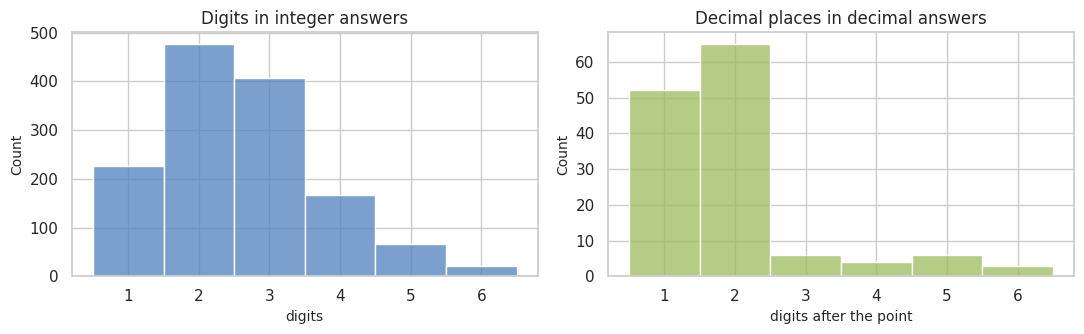

Most frequent answers: {'4': 36, '3': 35, '10': 28, '2': 25, '5': 25, '1': 24, '8': 23, '9': 21, '6': 21, '18': 20, '12': 19, '11': 19}


In [9]:
# ---- numeric structure of each format --------------------------------------
ints = train_ans[train_ans["a_type"] == "Integer"]["answer"]
decs = train_ans[train_ans["a_type"] == "Decimal"]["answer"]
fracs = train_ans[train_ans["a_type"] == "Fraction"]["answer"]

int_digits = ints.str.lstrip("-").str.len()
dec_places = decs.map(lambda s: -Decimal(s).as_tuple().exponent)
frac_parts = fracs.str.lstrip("-").str.split("/", expand=True).astype(int) if len(fracs) else pd.DataFrame(columns=[0, 1])
numer, denom = frac_parts[0], frac_parts[1]

vals = train_ans["value"].dropna()
sign = pd.Series({"positive": int((vals > 0).sum()), "zero": int((vals == 0).sum()), "negative": int((vals < 0).sum()),
                  "no exact value (Other/Missing)": int(train_ans["value"].isna().sum())})
frac_info = pd.Series({
    "fractions": len(fracs),
    "in lowest terms": int(sum(math.gcd(n, d) == 1 for n, d in zip(numer, denom) if d)) if len(fracs) else 0,
    "improper (numerator >= denominator)": int((numer >= denom).sum()) if len(fracs) else 0})

stats = pd.DataFrame({
    "integer digits": int_digits.describe(),
    "decimal places": dec_places.describe(),
    "numerator": numer.describe(),
    "denominator": denom.describe()}).round(2)
display(stats)
save_table(stats, "answer_numeric_stats")
print("Sign of answers:", sign.to_dict())
print("Fractions:", frac_info.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
if len(int_digits): sns.histplot(int_digits, discrete=True, ax=axes[0], color="#4f81bd")
axes[0].set_title("Digits in integer answers"); axes[0].set_xlabel("digits")
if len(dec_places): sns.histplot(dec_places, discrete=True, ax=axes[1], color="#9bbb59")
axes[1].set_title("Decimal places in decimal answers"); axes[1].set_xlabel("digits after the point")
plt.tight_layout(); plt.show()

top_vals = train_ans["answer"].value_counts().head(12)
print("Most frequent answers:", top_vals.to_dict())

**Why representation matters.** The grader compares strings. A numerically right answer written as `0.5` instead of `1/2` (or `9/10` written as `0.9`) scores 0.
Whether a problem expects an integer, decimal or fraction is therefore part of the task and is only partly predictable from the skill (see the per-skill chart);
the answer-type shares above tell how much format ambiguity remains within a skill. Final-answer extraction and formatting rules for later experiments should be designed per skill, based on these training statistics. Answers were **not** converted between formats anywhere in this notebook.

## 5. Problem statement analysis (training statements only)
Descriptive proxies, not difficulty measurements. Sentence count uses a simple heuristic: split after `. ! ?` when followed by whitespace and an uppercase letter/digit/quote/bracket (decimal points such as `3.5` are not split).

In [10]:
RE_NUM = re.compile(r"\d+(?:[.,]\d+)?(?:/\d+)?")
RE_SENT = re.compile(r"(?<=[.!?])\s+(?=[А-ЯІЇЄҐA-Z0-9«\"(])")
SYMBOLS = {"+": r"\+", "−/-": r"[−–-]", "×/*/·": r"[×*·]", "÷/:": r"[÷:]", "/": r"/", "=": r"=", "%": r"%", "()": r"\(", "<>": r"[<>]"}
UNITS = {"мм": r"\bмм\b", "см": r"\bсм\b", "дм": r"\bдм\b", "м": r"\bм\b", "км": r"\bкм\b", "г": r"\bг\b", "кг": r"\bкг\b",
         "т": r"\bт\b", "л": r"\bл\b", "хв": r"\bхв\b", "год": r"\bгод\b", "с": r"\bс\b", "грн": r"\bгрн\b",
         "га": r"\bга\b", "м²/см²": r"(?:м|см|км|дм)\s?[²2]\b", "°": r"°"}

st = train["statement"].fillna("")
feat = pd.DataFrame({"id": train["id"], "skill": train["skill"], "a_type": train_ans["a_type"]})
feat["n_chars"] = st.str.len()
feat["n_words"] = st.str.split().str.len()
feat["n_numbers"] = st.map(lambda s: len(RE_NUM.findall(s)))
feat["n_sentences"] = st.map(lambda s: max(1, len(RE_SENT.split(s.strip()))) if s.strip() else 0)
for k, pat in SYMBOLS.items(): feat["sym_" + k] = st.str.count(pat)
for k, pat in UNITS.items(): feat["unit_" + k] = st.str.count(pat)

display(feat[["n_chars", "n_words", "n_numbers", "n_sentences"]].describe().round(2))
sym_unit = pd.DataFrame({"statements_containing": {c[4:] if c.startswith("sym_") else c[5:]: int((feat[c] > 0).sum()) for c in feat.columns if c.startswith(("sym_", "unit_"))}})
sym_unit["pct"] = (100 * sym_unit["statements_containing"] / len(feat)).round(1)
display(sym_unit.sort_values("statements_containing", ascending=False).head(15))
save_table(feat.drop(columns=[]), "statement_features", index=False)

,n_chars,n_words,n_numbers,n_sentences
count,1526.00,1526.00,1526.00,1526.00
mean,44.92,8.26,2.24,1.34
std,32.86,5.24,1.52,0.65
min,11.00,2.00,1.00,1.00
25%,19.00,4.00,2.00,1.00
50%,31.00,7.00,2.00,1.00
75%,64.00,9.00,2.00,1.00
max,189.00,28.00,9.00,4.00


,statements_containing,pct
÷/:,721,47.2
+,194,12.7
−/-,193,12.6
×/*/·,174,11.4
/,150,9.8
=,115,7.5
км,73,4.8
год,67,4.4
%,59,3.9
см,59,3.9


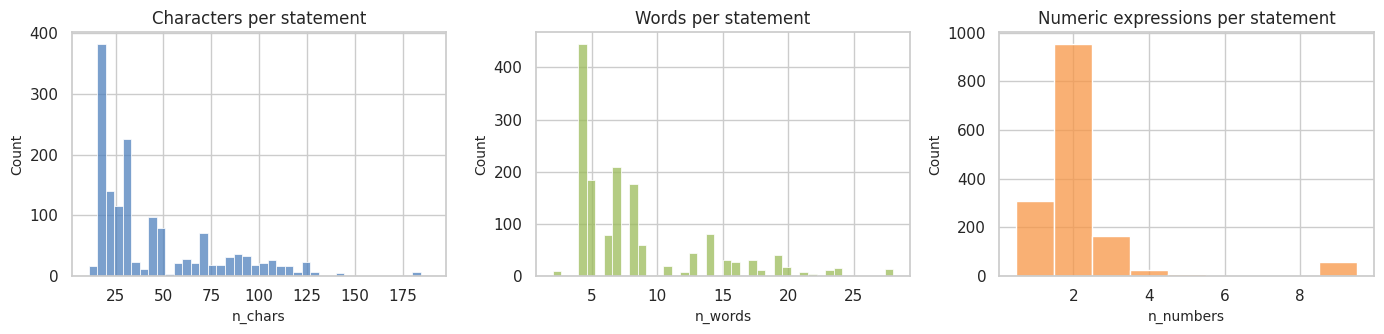

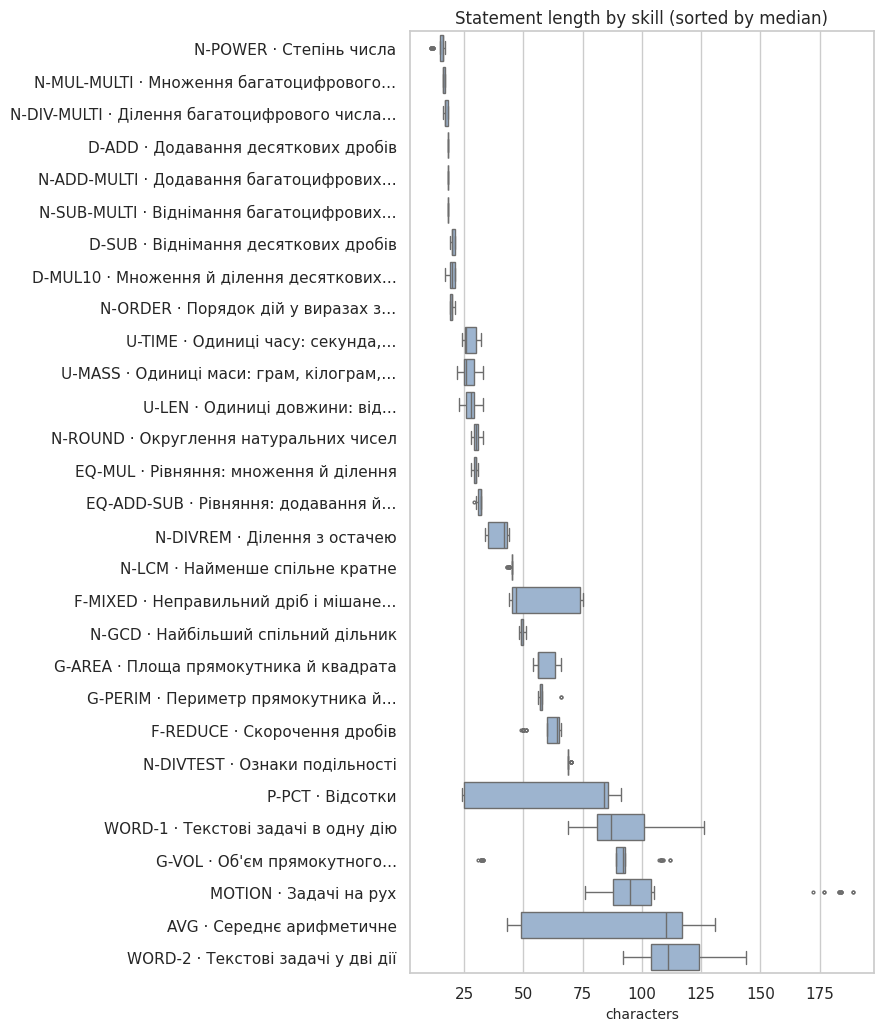

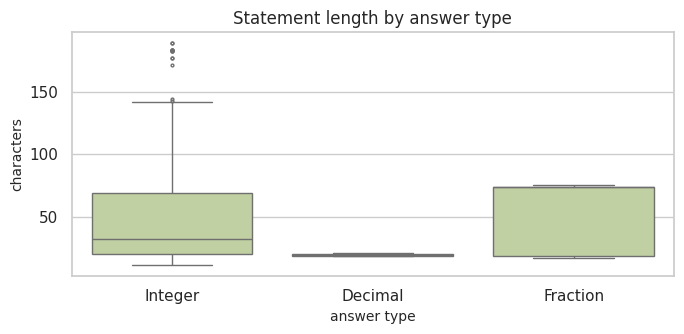

,median_chars,median_words,median_numbers,dominant_type,dominant_type_pct
skill,,,,,
AVG,110.0,19.0,4.0,Integer,100.0
D-ADD,18.0,4.0,2.0,Decimal,80.0
D-MUL10,20.0,4.0,2.0,Decimal,53.3
D-SUB,20.0,4.0,2.0,Decimal,100.0
EQ-ADD-SUB,32.0,7.0,2.0,Integer,100.0
EQ-MUL,30.0,7.0,2.0,Integer,100.0
F-MIXED,47.0,6.0,1.0,Integer,52.9
F-REDUCE,64.0,9.0,1.0,Integer,100.0
G-AREA,56.0,8.0,1.0,Integer,100.0


Spearman (n_chars vs n_numbers): 0.193


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(feat["n_chars"], bins=40, ax=axes[0], color="#4f81bd"); axes[0].set_title("Characters per statement")
sns.histplot(feat["n_words"], bins=40, ax=axes[1], color="#9bbb59"); axes[1].set_title("Words per statement")
sns.histplot(feat["n_numbers"], discrete=True, ax=axes[2], color="#f79646"); axes[2].set_title("Numeric expressions per statement")
plt.tight_layout(); plt.show()

order = feat.groupby("skill")["n_chars"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.2))
sns.boxplot(data=feat, y="skill", x="n_chars", order=order, ax=ax, color="#95b3d7", fliersize=2)
ax.set_yticklabels([skill_label(s, 30) for s in order]); ax.set_xlabel("characters"); ax.set_ylabel("")
ax.set_title("Statement length by skill (sorted by median)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
type_order = [t for t in ["Integer", "Decimal", "Fraction", "Other"] if t in set(feat["a_type"])]
sns.boxplot(data=feat, x="a_type", y="n_chars", order=type_order, ax=ax, color="#c4d79b", fliersize=2)
ax.set_title("Statement length by answer type"); ax.set_xlabel("answer type"); ax.set_ylabel("characters")
plt.tight_layout(); plt.show()

per_skill = feat.groupby("skill").agg(median_chars=("n_chars", "median"), median_words=("n_words", "median"),
                                      median_numbers=("n_numbers", "median"),
                                      dominant_type=("a_type", lambda s: s.value_counts().index[0]),
                                      dominant_type_pct=("a_type", lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 1)))
display(per_skill.loc[sorted(per_skill.index, key=natural_key)])
save_table(per_skill, "statement_stats_by_skill")
print("Spearman (n_chars vs n_numbers):", round(feat["n_chars"].corr(feat["n_numbers"], method="spearman"), 3))

In [12]:
# Very short / very long training statements (5 each, truncated).
q05, q95 = feat["n_chars"].quantile([0.05, 0.95])
print(f"5th / 95th percentile of length: {q05:.0f} / {q95:.0f} chars")
for title, idx in [("Shortest", feat["n_chars"].nsmallest(5).index), ("Longest", feat["n_chars"].nlargest(5).index)]:
    print(f"\n{title}:")
    for i in idx:
        print(f"  [{train.loc[i, 'skill']}] ({feat.loc[i, 'n_chars']} chars) {textwrap.shorten(st[i], 150, placeholder='…')}")

# Common vocabulary: crude Ukrainian stop-word list, tokens with >= 3 letters.
STOP = set("що це від для при або яке який яка які його вона вони так але коли буде було були був має мають через після тому щоб потім також всього усього на за до по із зі та не як той ця ці цей його її їх про під між над ще вже тільки більше менше".split())
tokens = Counter(w for s in st for w in re.findall(r"[^\W\d_]+", s.casefold()) if len(w) >= 3 and w not in STOP)
display(pd.DataFrame(tokens.most_common(25), columns=["token", "count"]).T)

# Share of statements containing selected mathematical stems (descriptive vocabulary check).
STEMS = ["скільки", "знайд", "обчисл", "площ", "периметр", "відсот", "дроб", "середн", "швидк", "кут", "трикутник",
         "прямокут", "сум", "різниц", "добут", "частк", "рівнян", "найбільш", "найменш", "округл", "довжин", "об'єм|обʼєм|об’єм"]
stem_tbl = pd.Series({s: round(100 * st.str.casefold().str.contains(s, regex=True).mean(), 1) for s in STEMS}, name="% statements")
display(stem_tbl.sort_values(ascending=False).head(15).to_frame().T)

5th / 95th percentile of length: 16 / 110 chars

Shortest:
  [N-POWER] (11 chars) Обчисли: 6²
  [N-POWER] (11 chars) Обчисли: 9³
  [N-POWER] (11 chars) Обчисли: 4³
  [N-POWER] (11 chars) Обчисли: 4²
  [N-POWER] (11 chars) Обчисли: 7³

Longest:
  [MOTION] (189 chars) Назустріч одне одному одночасно виїхали два велосипедисти. Швидкість першого 13 км/год, швидкість другого 19 км/год. Вони зустрілися через 8 год. Яка…
  [MOTION] (189 chars) Назустріч одне одному одночасно виїхали два велосипедисти. Швидкість першого 20 км/год, швидкість другого 19 км/год. Вони зустрілися через 3 год. Яка…
  [MOTION] (184 chars) Назустріч одне одному одночасно виїхали два автобуси. Швидкість першого 78 км/год, швидкість другого 56 км/год. Вони зустрілися через 6 год. Яка була…
  [MOTION] (184 chars) Назустріч одне одному одночасно вирушили два потяги. Швидкість першого 76 км/год, швидкість другого 110 км/год. Вони зустрілися через 6 год. Яка була…
  [MOTION] (184 chars) Назустріч одне одному одночасно виїха

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
token,обчисли,знайди,скільки,чисел,розв,яжи,рівняння,дріб,год,переведи,...,ділення,дорівнює,найбільший,спільний,дільник,яблук,становить,тіні,найменше,спільне
count,515,322,229,177,115,115,115,114,112,109,...,58,54,51,51,51,49,47,44,43,43


,обчисл,знайд,скільки,рівнян,довжин,найбільш,округл,швидк,середн,об'єм|обʼєм|об’єм,найменш,площ,кут,дроб,частк
% statements,33.7,21.1,15.0,7.5,6.0,4.3,3.9,3.9,3.9,2.8,2.8,2.6,2.2,2.2,2.2


**Reading these results:** length, word count and numeric-expression count are rough proxies for how much text/number processing a problem involves; they do not measure mathematical difficulty. A skill with long statements and few numbers may be a word problem, while short statements with many numbers may be a direct computation. Such differences are hypotheses to test against actual model accuracy later, not conclusions.

## 6–8. Annotation columns: `steps`, `hints`, `typical_errors`
All three columns are first **inspected raw** (what do the strings look like?), then parsed safely with `json.loads` → `ast.literal_eval` (never `eval`).
Status categories: **missing** (empty cell) · **parse_error** (non-empty but unparseable) · **empty** (parsed to an empty list/dict) · **ok**.

In [13]:
def safe_parse(x):
    # Returns (status, obj). Status: missing / parse_error / empty / ok.
    if pd.isna(x) or str(x).strip() == "": return "missing", None
    s = str(x).strip()
    for fn in (json.loads, ast.literal_eval):
        try: obj = fn(s)
        except Exception: continue
        if obj is None or (hasattr(obj, "__len__") and len(obj) == 0): return "empty", obj
        return "ok", obj
    return "parse_error", None

def as_items(obj):
    # Normalise a parsed object to a list of items.
    if obj is None: return []
    if isinstance(obj, dict): return list(obj.values())
    if isinstance(obj, (list, tuple)): return list(obj)
    return [obj]

def signature(obj):
    # Compact description of the structure of a parsed object.
    if isinstance(obj, dict): return f"dict(keys={sorted(map(str, obj))[:6]})"
    if isinstance(obj, (list, tuple)):
        inner = Counter(("dict" + str(sorted(map(str, i))[:5])) if isinstance(i, dict) else type(i).__name__ for i in obj)
        return f"{type(obj).__name__}[{', '.join(f'{k}×{v}' for k, v in inner.most_common(3))}]"
    return type(obj).__name__

def item_text(i):
    return i if isinstance(i, str) else json.dumps(i, ensure_ascii=False)

def inspect_column(col, n_raw=2):
    raw = train[col]
    print(f"=== {col} ===")
    print("first characters:", Counter(raw.dropna().str.strip().str[:1]).most_common(5))
    for r in raw.dropna().head(n_raw): print("  raw:", textwrap.shorten(r, 160, placeholder="…"))
    parsed = raw.map(safe_parse)
    status = parsed.map(lambda t: t[0])
    print("parse status:", status.value_counts().to_dict())
    sigs = Counter(signature(o) for s, o in parsed if s == "ok")
    print("top structures:", sigs.most_common(4))
    fails = raw[status == "parse_error"]
    if len(fails): print("parse-error examples:", [textwrap.shorten(f, 80, placeholder="…") for f in fails.head(2)])
    return parsed

ann = pd.DataFrame({"id": train["id"], "skill": train["skill"], "a_type": train_ans["a_type"], "n_chars": feat["n_chars"]})

### 6. Intermediate steps (`steps`)

=== steps ===
first characters: [('[', 1526)]
  raw: []
  raw: []
parse status: {'empty': 798, 'ok': 728}
top structures: [('list[str×1]', 664), ('list[str×2]', 64)]

Share with non-empty steps: 47.7%


,count,pct
steps_status,,
empty,798,52.29
ok,728,47.71


,count,mean,std,min,25%,50%,75%,max
n_steps (non-empty only),728.0,1.09,0.28,1.0,1.0,1.0,1.0,2.0


skill,AVG,D-ADD,D-MUL10,D-SUB,EQ-ADD-SUB,EQ-MUL,F-MIXED,F-REDUCE,G-AREA,G-PERIM,...,N-ORDER,N-POWER,N-ROUND,N-SUB-MULTI,P-PCT,U-LEN,U-MASS,U-TIME,WORD-1,WORD-2
pct_with_steps,100.0,100.0,0.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,...,100.0,76.2,0.0,100.0,100.0,0.0,0.0,0.0,0.0,100.0
median_n_steps,1.0,1.0,NaN,1.0,NaN,NaN,1.0,NaN,NaN,NaN,...,1.0,1.0,NaN,1.0,1.0,NaN,NaN,NaN,NaN,1.0


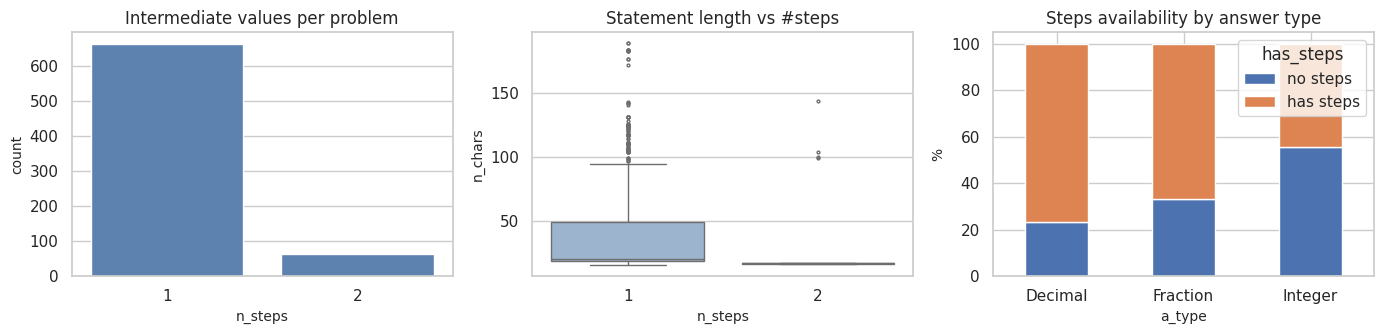

Spearman(n_steps, n_chars) = -0.393

[N-MUL-MULTI] Обчисли: 112 × 49
  answer: 5488 | steps: ['1008', '4480']

[N-POWER] Обчисли: 4⁵ + 39
  answer: 1063 | steps: ['1024']

[N-ORDER] Обчисли: 90 - 11 × 4
  answer: 46 | steps: ['44']


In [14]:
p_steps = inspect_column("steps")
ann["steps_status"] = p_steps.map(lambda t: t[0])
ann["n_steps"] = p_steps.map(lambda t: len(as_items(t[1])))
ann["has_steps"] = ann["steps_status"].eq("ok")

print("\nShare with non-empty steps: %.1f%%" % (100 * ann["has_steps"].mean()))
display(ann["steps_status"].value_counts().to_frame("count").assign(pct=lambda d: (100 * d["count"] / len(ann)).round(2)))
display(ann.loc[ann["has_steps"], "n_steps"].describe().round(2).to_frame("n_steps (non-empty only)").T)

steps_skill = ann.groupby("skill").agg(pct_with_steps=("has_steps", lambda s: round(100 * s.mean(), 1)),
                                       median_n_steps=("n_steps", lambda s: s[s > 0].median() if (s > 0).any() else np.nan))
display(steps_skill.loc[sorted(steps_skill.index, key=natural_key)].T)
save_table(steps_skill, "steps_by_skill")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.countplot(x=ann.loc[ann["has_steps"], "n_steps"], ax=axes[0], color="#4f81bd"); axes[0].set_title("Intermediate values per problem")
sns.boxplot(data=ann[ann["has_steps"]], x="n_steps", y="n_chars", ax=axes[1], color="#95b3d7", fliersize=2)
axes[1].set_title("Statement length vs #steps")
tmp = pd.crosstab(ann["a_type"], ann["has_steps"], normalize="index").mul(100).rename(columns={True: "has steps", False: "no steps"})
tmp.plot(kind="bar", stacked=True, ax=axes[2], rot=0); axes[2].set_title("Steps availability by answer type"); axes[2].set_ylabel("%")
plt.tight_layout(); plt.show()

sub = ann[ann["has_steps"]]
if len(sub) > 2 and sub["n_steps"].nunique() > 1:
    print("Spearman(n_steps, n_chars) =", round(sub["n_steps"].corr(sub["n_chars"], method="spearman"), 3))

# Small reproducible sample of parsed examples (training only).
for i in train[ann["has_steps"]].sample(min(3, int(ann["has_steps"].sum())), random_state=SEED).index:
    print(f"\n[{train.loc[i, 'skill']}] {textwrap.shorten(train.loc[i, 'statement'], 140, placeholder='…')}")
    print("  answer:", train.loc[i, "answer"], "| steps:", p_steps[i][1])

**Interpretation.** The number of intermediate values is a proxy for multi-step structure — not the exact number of reasoning steps — and the values are **not** worked solutions (no operations or explanations).
Possible future uses: (a) a *checkable* signal to verify teacher- or model-generated solutions (do the intermediate numbers appear and does the chain end at the canonical answer?); (b) a skeleton for structured chain-of-thought supervision; (c) filtering synthetic solutions for SFT. All of these must use training-split problems only. They would still need a teacher (an allowed open model) or an independently written generator to produce the actual text of the reasoning.

### 7. Hints (`hints`)

=== hints ===
first characters: [('[', 1526)]
  raw: ["Яка з одиниць, «год» чи «хв», більша? Скільки менших одиниць міститься в одній більшій?", "Ми переходимо до менших одиниць, тому їх потрібно більше:…
  raw: ["Для кожного числа окремо перевір ознаку подільності на 2. Згадай, на яку саму цифру чи суму цифр дивляться.", "Число ділиться на це, якщо закінчується парною…
parse status: {'ok': 1526}
top structures: [('list[str×3]', 1526)]


,count
hints_status,
ok,1526


Hints per problem: {3: 1526}
Exactly three hints: 100.0% of problems


skill,AVG,D-ADD,D-MUL10,D-SUB,EQ-ADD-SUB,EQ-MUL,F-MIXED,F-REDUCE,G-AREA,G-PERIM,...,N-ORDER,N-POWER,N-ROUND,N-SUB-MULTI,P-PCT,U-LEN,U-MASS,U-TIME,WORD-1,WORD-2
pct_with_hints,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
mean_n_hints,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
median_chars_per_hint,102.7,91.7,104.0,105.7,89.7,83.3,101.0,145.7,100.7,85.7,...,100.7,83.7,164.3,109.3,111.0,95.3,94.7,97.0,122.7,93.0


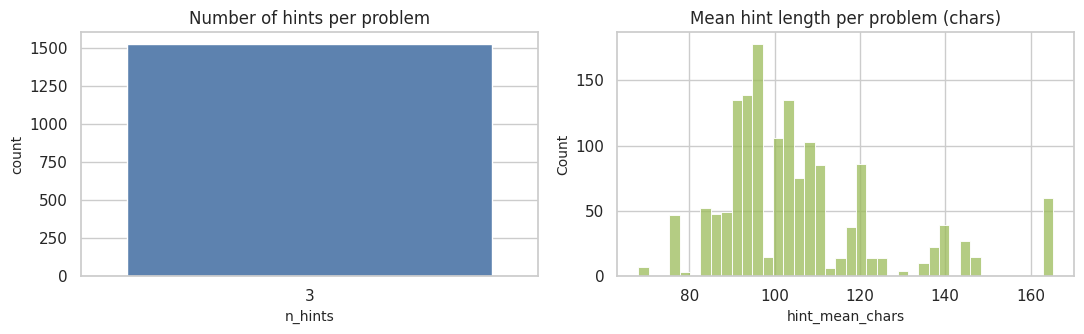


[U-LEN] Запиши в метрах: 7 км 318 м.
   - Яка з одиниць, «км» чи «м», більша? Скільки менших одиниць міститься в одній більшій?
   - Спочатку переведи більшу одиницю в меншу, а потім додай решту.
   - Згадай співвідношення: одна одиниця «км» дорівнює тисячі одиницям «м». Подумай, чи має відповідь стати більшою, чи меншою за дане число.

[U-MASS] Запиши в кілограмах: 18 ц 51 кг.
   - Яка з одиниць, «ц» чи «кг», більша? Скільки менших одиниць міститься в одній більшій?
   - Спочатку переведи більшу одиницю в меншу, а потім додай решту.
   - Згадай співвідношення: одна одиниця «ц» дорівнює ста одиницям «кг». Подумай, чи має відповідь стати більшою, чи меншою за дане число.

[N-POWER] Обчисли: 2³ + 3
   - Степінь показує, скільки разів число-основу беремо множником. Яке число тут основа, а що означає маленьке число над ним?
   - Куб числа це число, помножене на себе, а результат ще раз на це саме число.
   - Спершу знайди степінь, потім додай чи відніми. Не плутай степінь з множенням на п

In [15]:
p_hints = inspect_column("hints")
ann["hints_status"] = p_hints.map(lambda t: t[0])
ann["n_hints"] = p_hints.map(lambda t: len(as_items(t[1])))
ann["has_hints"] = ann["hints_status"].eq("ok")
ann["hint_chars"] = p_hints.map(lambda t: sum(len(item_text(i)) for i in as_items(t[1])))
ann["hint_mean_chars"] = ann["hint_chars"] / ann["n_hints"].replace(0, np.nan)

display(ann["hints_status"].value_counts().to_frame("count"))
print("Hints per problem:", ann["n_hints"].value_counts().sort_index().to_dict())
print("Exactly three hints: %.1f%% of problems" % (100 * (ann["n_hints"] == 3).mean()))

hints_skill = ann.groupby("skill").agg(pct_with_hints=("has_hints", lambda s: round(100 * s.mean(), 1)),
                                       mean_n_hints=("n_hints", "mean"), median_chars_per_hint=("hint_mean_chars", "median")).round(1)
display(hints_skill.loc[sorted(hints_skill.index, key=natural_key)].T)
save_table(hints_skill, "hints_by_skill")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=ann["n_hints"], ax=axes[0], color="#4f81bd"); axes[0].set_title("Number of hints per problem")
sns.histplot(ann["hint_mean_chars"].dropna(), bins=40, ax=axes[1], color="#9bbb59"); axes[1].set_title("Mean hint length per problem (chars)")
plt.tight_layout(); plt.show()

# At most three representative training examples.
for i in train[ann["has_hints"]].sample(min(3, int(ann["has_hints"].sum())), random_state=SEED).index:
    print(f"\n[{train.loc[i, 'skill']}] {textwrap.shorten(train.loc[i, 'statement'], 120, placeholder='…')}")
    for h in as_items(p_hints[i][1]): print("   -", textwrap.shorten(item_text(h), 140, placeholder="…"))

**Possible later use (training-split only).**
- *Few-shot demonstrations:* hints of a **training** problem could be turned into short worked examples for the same skill.
- *Teacher guidance:* an allowed open teacher model could be given a training problem plus its hints to write a solution, which is then filtered by the final answer (and `steps`).
- *Scaffolded supervision:* graded hints (vague → specific) suggest a natural curriculum for reasoning traces.

**Hard rules.** Hints do not exist for test problems, so they are **not** inference-time features. During validation, the hints (and answer / steps / typical errors) of the problem being evaluated — and of every validation problem — must never be shown to the model or used to build training or few-shot data.

### 8. Typical errors (`typical_errors`)

=== typical_errors ===
first characters: [('[', 1526)]
  raw: [{"id": "wrong_direction", "value": "1/6", "explanation": "Схоже, напрямок переведення переплутано. Коли переходимо до менших одиниць, число збільшується, а до…
  raw: [{"id": "digit_sum_rule", "value": "6", "explanation": "Схоже, застосовано ознаку, яка стосується суми цифр. Для цього дільника дивляться лише на останню цифру…
parse status: {'ok': 1526}
top structures: [("list[dict['explanation', 'id', 'value']×1]", 829), ("list[dict['explanation', 'id', 'value']×2]", 697)]


,count
err_status,
ok,1526


Wrong answers per problem: {1: 829, 2: 697}
Wrong-answer entries where no answer value could be extracted: 0
Annotated wrong answers identical (string) to the canonical answer: 0
...numerically equal but written differently: 0
Problems with duplicate rejected answers: 0
Wrong-answer format types: {'Integer': 1816, 'Fraction': 228, 'Decimal': 179}
Share of wrong answers with the same format type as the correct answer: 87.1%
Metadata fields next to each wrong answer: {'id': 2223, 'explanation': 2223}
  field 'id': 57 unique values -> looks free text; top: —
  field 'explanation': 68 unique values -> looks free text; top: —


skill,AVG,D-ADD,D-MUL10,D-SUB,EQ-ADD-SUB,EQ-MUL,F-MIXED,F-REDUCE,G-AREA,G-PERIM,...,N-ORDER,N-POWER,N-ROUND,N-SUB-MULTI,P-PCT,U-LEN,U-MASS,U-TIME,WORD-1,WORD-2
pct_with_errors,100.0,100.0,100.0,100.0,100.0,100.00,100.0,100.00,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.00,100.00,100.0,100.00,100.0
mean_n_wrong,2.0,1.0,1.7,1.0,1.0,1.29,2.0,1.75,2.0,2.0,...,1.0,1.0,1.0,1.0,2.0,1.48,1.79,2.0,1.22,2.0


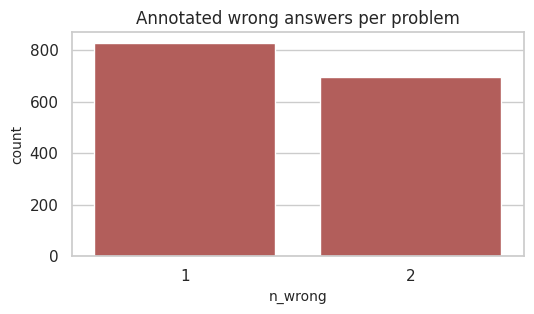

id=02d631  correct=600  wrong=1/6  meta={'id': 'wrong_direction', 'explanation': 'Схоже, напрямок переведення переплутано. Коли переходимо…
id=02d631  correct=600  wrong=1000  meta={'id': 'decimal_system', 'explanation': "Схоже, час перераховано за десятковою системою. Але…
id=4c2249  correct=4  wrong=6  meta={'id': 'digit_sum_rule', 'explanation': 'Схоже, застосовано ознаку, яка стосується суми цифр. Для…


In [16]:
p_err = inspect_column("typical_errors")
RE_ANY_NUM = re.compile(r"-?\d+(?:[.,]\d+)?(?:/\d+)?")
ANS_KEYS = ("answer", "wrong_answer", "wrong", "incorrect", "incorrect_answer", "value", "result", "ans")

def extract_wrong(obj):
    # Returns list of (wrong_answer or None, metadata dict). Heuristic over the structures actually found.
    out = []
    if isinstance(obj, dict):
        if obj and all(RE_ANY_NUM.fullmatch(str(k).strip()) for k in obj):          # {"123": "explanation", ...}
            return [(str(k).strip(), {"description": v}) for k, v in obj.items()]
        obj = [obj]                                                               # single record
    if isinstance(obj, (list, tuple)):
        for it in obj:
            if isinstance(it, dict):
                key = next((k for k in it if str(k).lower() in ANS_KEYS), None)
                if key is None:
                    key = next((k for k, v in it.items() if isinstance(v, (int, float, str)) and RE_ANY_NUM.fullmatch(str(v).strip())), None)
                out.append((str(it[key]).strip() if key is not None else None, {k: v for k, v in it.items() if k != key}))
            elif isinstance(it, (int, float, str)): out.append((str(it).strip(), {}))
            elif isinstance(it, (list, tuple)) and it: out.append((str(it[0]).strip(), {"extra": list(it[1:])}))
            else: out.append((None, {}))
    return out

wrong = p_err.map(lambda t: extract_wrong(t[1]) if t[0] == "ok" else [])
ann["err_status"] = p_err.map(lambda t: t[0])
ann["n_wrong"] = wrong.map(len)
ann["has_errors"] = ann["err_status"].eq("ok") & (ann["n_wrong"] > 0)

wrong_flat = pd.DataFrame([{"id": train.loc[i, "id"], "skill": train.loc[i, "skill"], "correct": train.loc[i, "answer"], "wrong": w, "meta": m}
                           for i, lst in wrong.items() for (w, m) in lst])
n_unextractable = int(wrong_flat["wrong"].isna().sum()) if len(wrong_flat) else 0

display(ann["err_status"].value_counts().to_frame("count"))
print("Wrong answers per problem:", ann["n_wrong"].value_counts().sort_index().to_dict())
print("Wrong-answer entries where no answer value could be extracted:", n_unextractable)

if len(wrong_flat):
    wf = wrong_flat.dropna(subset=["wrong"]).copy()
    wf["same_string_as_correct"] = wf["wrong"] == wf["correct"]
    def num_eq(a, b):
        x, y = exact_value(a.replace(",", ".")), exact_value(b)
        return x is not None and y is not None and x == y
    wf["numerically_equal_to_correct"] = [num_eq(w, c) for w, c in zip(wf["wrong"], wf["correct"])]
    dup_within = int(sum(len(g) != g["wrong"].nunique() for _, g in wf.groupby("id")))
    wf["wrong_type"] = wf["wrong"].map(classify_answer)
    print("Annotated wrong answers identical (string) to the canonical answer:", int(wf["same_string_as_correct"].sum()))
    print("...numerically equal but written differently:", int((wf["numerically_equal_to_correct"] & ~wf["same_string_as_correct"]).sum()))
    print("Problems with duplicate rejected answers:", dup_within)
    print("Wrong-answer format types:", wf["wrong_type"].value_counts().to_dict())
    same_type = (wf["wrong_type"].to_numpy(dtype=object) == wf["correct"].map(classify_answer).to_numpy(dtype=object)).mean()
    print("Share of wrong answers with the same format type as the correct answer: %.1f%%" % (100 * same_type))
    meta_keys = Counter(k for m in wf["meta"] for k in m)
    print("Metadata fields next to each wrong answer:", dict(meta_keys) or "none (answers only)")
    for k in list(meta_keys)[:3]:
        vals = pd.Series([str(m.get(k)) for m in wf["meta"] if k in m])
        kind = "categorical" if vals.nunique() <= 30 else "free text"
        print(f"  field '{k}': {vals.nunique()} unique values -> looks {kind}; top: {vals.value_counts().head(3).to_dict() if kind == 'categorical' else '—'}")
else:
    wf, dup_within, meta_keys = pd.DataFrame(), 0, Counter()
    print("No typical-error annotations could be extracted.")

err_skill = ann.groupby("skill").agg(pct_with_errors=("has_errors", lambda s: round(100 * s.mean(), 1)), mean_n_wrong=("n_wrong", "mean")).round(2)
display(err_skill.loc[sorted(err_skill.index, key=natural_key)].T)
save_table(err_skill, "typical_errors_by_skill")

fig, ax = plt.subplots(figsize=(5.5, 3.3))
sns.countplot(x=ann["n_wrong"], ax=ax, color="#c0504d"); ax.set_title("Annotated wrong answers per problem")
plt.tight_layout(); plt.show()
if len(wf):
    for _, r in wf.head(3).iterrows():
        print(f"id={r['id']}  correct={r['correct']}  wrong={r['wrong']}  meta={textwrap.shorten(str(r['meta']), 100, placeholder='…')}")

**Notes.** Misconception categories are only reported if they exist as explicit fields (see output above); none are invented.
For DPO, a numeric wrong answer is **not** a full rejected response: preference pairs would need a rejected *reasoning trace ending in that wrong answer* (e.g., sampled from an allowed model and filtered for a matching wrong final answer, or written by an independent generator), paired with a verified chosen solution. Typical errors can also support aggregate error analysis (how often does a model's wrong answer coincide with an annotated misconception?) — on the **validation** set only for evaluation, never for training.

## 9. Duplicate and template-similarity analysis (training data)
- **Exact duplicate:** identical strings.  **Normalized duplicate:** identical after Unicode NFKC, case folding and whitespace collapsing.
- **Near duplicate:** very similar text (character TF-IDF cosine similarity) but not identical.
- **Template-sharing problems:** the same text once numbers are replaced by `<NUM>`; these are *different problems* with a common structure.

Signatures are used **only** to detect repeated templates and possible split contamination — never to solve anything.

In [17]:
RE_SIG = re.compile(r"\d+(?:[.,/]\d+)*")
def template_signature(s):
    return RE_SIG.sub("<NUM>", normalize_text(s))

train["_norm"] = t_norm
train["_sig"] = train["statement"].fillna("").map(template_signature)

exact_dup = train["statement"].duplicated(keep=False)
norm_dup = train["_norm"].duplicated(keep=False)
conflict = train[norm_dup].groupby("_norm")["answer"].nunique()
n_conflict_groups = int((conflict > 1).sum())

sig_sizes = train.groupby("_sig")["id"].transform("size")
sig_groups = train.groupby("_sig").agg(n=("id", "size"), n_answers=("answer", "nunique"), n_skills=("skill", "nunique"))
print(f"Exact duplicate rows (all members of duplicate groups): {int(exact_dup.sum())}")
print(f"Normalized duplicate rows: {int(norm_dup.sum())} in {train.loc[norm_dup, '_norm'].nunique()} groups")
print(f"Normalized-duplicate groups with conflicting answers: {n_conflict_groups}")
print(f"Distinct template signatures: {len(sig_groups)} (for {len(train)} problems)")
print(f"Problems sharing a template with >=1 other problem: {int((sig_sizes > 1).sum())} ({100 * (sig_sizes > 1).mean():.1f}%)")
print("Template group size distribution (top):", sig_groups["n"].value_counts().sort_index().head(8).to_dict())
display(train.assign(shared_template=sig_sizes > 1).groupby("skill")["shared_template"].mean().mul(100).round(1)
        .loc[sorted(train["skill"].unique(), key=natural_key)].to_frame("% problems in shared template").T)

print("\nLargest template groups (signature truncated):")
for sig, r in sig_groups.sort_values("n", ascending=False).head(3).iterrows():
    print(f"  n={r['n']}, distinct answers={r['n_answers']}, skills={r['n_skills']}: {textwrap.shorten(sig, 140, placeholder='…')}")
if conflict.gt(1).any():
    ex = conflict[conflict > 1].index[0]
    print("\nExample conflicting-answer duplicate group:")
    display(train[train["_norm"] == ex][["id", "skill", "answer"]].head(4))

Exact duplicate rows (all members of duplicate groups): 0
Normalized duplicate rows: 0 in 0 groups
Normalized-duplicate groups with conflicting answers: 0
Distinct template signatures: 209 (for 1526 problems)
Problems sharing a template with >=1 other problem: 1458 (95.5%)
Template group size distribution (top): {1: 68, 2: 44, 3: 20, 4: 14, 5: 8, 6: 7, 7: 6, 8: 2}


skill,AVG,D-ADD,D-MUL10,D-SUB,EQ-ADD-SUB,EQ-MUL,F-MIXED,F-REDUCE,G-AREA,G-PERIM,...,N-ORDER,N-POWER,N-ROUND,N-SUB-MULTI,P-PCT,U-LEN,U-MASS,U-TIME,WORD-1,WORD-2
% problems in shared template,96.7,100.0,100.0,100.0,100.0,100.0,100.0,100.0,93.8,93.3,...,100.0,100.0,100.0,100.0,100.0,96.4,100.0,100.0,62.7,61.7



Largest template groups (signature truncated):
  n=138, distinct answers=125, skills=3: обчисли: <NUM> + <NUM>
  n=129, distinct answers=119, skills=3: обчисли: <NUM> - <NUM>
  n=92, distinct answers=92, skills=2: обчисли: <NUM> × <NUM>


In [18]:
# Near-duplicates via character TF-IDF (lightweight, 1.5k x 1.5k).
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
X = vec.fit_transform(train["_norm"])
sim = (X @ X.T).toarray()
codes = pd.factorize(train["_norm"])[0]
same_norm = codes[:, None] == codes[None, :]
sim_nd = np.triu(np.where(same_norm, 0.0, sim), k=1)          # unordered pairs, excluding exact/normalized duplicates
def eq_matrix(series):
    v = series.to_numpy(dtype=object)          # plain numpy: avoids pandas string-array broadcasting limits
    return v[:, None] == v[None, :]
same_sig, same_skill, same_ans = eq_matrix(train["_sig"]), eq_matrix(train["skill"]), eq_matrix(train["answer"])

rows = []
for thr in (0.8, 0.9, 0.95):
    m = sim_nd >= thr
    rows.append({"threshold": thr, "near-dup pairs": int(m.sum()), "same template signature": int((m & same_sig).sum()),
                 "same skill": int((m & same_skill).sum()),
                 "same answer string": int((m & same_ans).sum())})
near_tbl = pd.DataFrame(rows)
display(near_tbl)
save_table(near_tbl, "near_duplicate_pairs", index=False)

flat = np.argsort(sim_nd, axis=None)[::-1][:3]
print("Three most similar non-identical pairs:")
for f in flat:
    i, j = np.unravel_index(f, sim_nd.shape)
    print(f"  sim={sim_nd[i, j]:.3f}  ids=({train.loc[i, 'id']}, {train.loc[j, 'id']})  same_template={bool(same_sig[i, j])}")
    print("    A:", textwrap.shorten(train.loc[i, "statement"], 130, placeholder="…"))
    print("    B:", textwrap.shorten(train.loc[j, "statement"], 130, placeholder="…"))

dup_stats = {"exact_dup_rows": int(exact_dup.sum()), "norm_dup_rows": int(norm_dup.sum()), "norm_dup_conflict_groups": n_conflict_groups,
             "n_templates": len(sig_groups), "pct_in_shared_template": round(100 * (sig_sizes > 1).mean(), 1),
             "near_pairs_ge_0.9": int(near_tbl.loc[near_tbl.threshold == 0.9, "near-dup pairs"].iloc[0])}

,threshold,near-dup pairs,same template signature,same skill,same answer string
0,0.80,3831,2616,3707,174
1,0.90,1055,739,1050,42
2,0.95,310,204,309,18


Three most similar non-identical pairs:
  sim=0.996  ids=(5334c8, 375235)  same_template=True
    A: Туристична група йде зі сталою швидкістю 3 км/год. Яку відстань подолано за 4 год? Відповідь дай у км.
    B: Туристична група йде зі сталою швидкістю 3 км/год. Яку відстань подолано за 7 год? Відповідь дай у км.
  sim=0.996  ids=(53069b, 7ba481)  same_template=True
    A: Ящик має форму прямокутного паралелепіпеда з довжиною 11 дм, шириною 4 дм і висотою 5 дм. Знайди його об'єм.
    B: Ящик має форму прямокутного паралелепіпеда з довжиною 2 дм, шириною 11 дм і висотою 4 дм. Знайди його об'єм.
  sim=0.993  ids=(4d52f4, 6ac8da)  same_template=True
    A: Назустріч одне одному одночасно виїхали два велосипедисти. Швидкість першого 13 км/год, швидкість другого 19 км/год. Вони…
    B: Назустріч одне одному одночасно виїхали два велосипедисти. Швидкість першого 20 км/год, швидкість другого 19 км/год. Вони…


**Distinctions.** *Exact/normalized duplicates* are the same problem → they must stay on one side of the split. *Near duplicates* are almost the same text (typos, small rewording) → possible leakage, quantified rather than removed. *Template-sharing problems* have different numbers and usually different answers → legitimate separate problems, but validation accuracy may be optimistic if a model learns a template from similar training items (that is also what the test set will probably contain, so some template overlap is realistic rather than a bug).

## 10. Fixed validation split (80 / 20)
- `random_state = 42`, stratified by `skill`.
- Rows with identical *normalized* statements form a group and always stay together. If no such groups exist, a plain stratified `train_test_split` is used; otherwise `StratifiedGroupKFold(n_splits=5)` (first fold = validation, ≈20%) and the deviation from 20% is reported.
- This split is **frozen** and must be reused by every later notebook.

**Data-use policy.** Validation questions are used only to *evaluate*. Validation answers, hints, steps and typical errors must never appear in training data, teacher-generated training data, few-shot demonstrations or prompts. Validation answers may be used for scoring and aggregate error analysis only.

In [19]:
group_id = pd.factorize(train["_norm"])[0]
has_dup_groups = pd.Series(group_id).duplicated().any()
all_idx = np.arange(len(train))
if not has_dup_groups:
    idx_tr, idx_va = train_test_split(all_idx, test_size=0.2, stratify=train["skill"], random_state=SEED)
    split_method = "train_test_split(test_size=0.2, stratify=skill, random_state=42)"
else:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    idx_tr, idx_va = next(sgkf.split(all_idx, train["skill"], groups=group_id))
    split_method = "StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), fold 0 = validation; groups = normalized statements"
idx_tr, idx_va = np.sort(idx_tr), np.sort(idx_va)

train_split = train.iloc[idx_tr].drop(columns=["_norm", "_sig"]).reset_index(drop=True)
val_split = train.iloc[idx_va].drop(columns=["_norm", "_sig"]).reset_index(drop=True)

# ---- sanity checks -----------------------------------------------------------
assert set(train_split["id"]).isdisjoint(val_split["id"]), "ID overlap between splits"
assert len(train_split) + len(val_split) == len(train)
assert set(train_split["skill"]) == set(val_split["skill"]) == set(train["skill"]), "A skill is missing from one split"
assert set(group_id[idx_tr]).isdisjoint(group_id[idx_va]), "Duplicate statements are split across subsets"
print("Method:", split_method)
print(f"train={len(train_split)} ({100 * len(train_split) / len(train):.2f}%)  validation={len(val_split)} ({100 * len(val_split) / len(train):.2f}%)")
print("Checks passed: disjoint ids, all skills in both subsets, duplicate groups kept together.")

# ---- distribution comparison -----------------------------------------------
skill_cmp = pd.DataFrame({"train": train_split["skill"].value_counts(), "validation": val_split["skill"].value_counts()}).fillna(0).astype(int)
skill_cmp["val_pct_of_skill"] = (100 * skill_cmp["validation"] / (skill_cmp["train"] + skill_cmp["validation"])).round(1)
display(skill_cmp.loc[sorted(skill_cmp.index, key=natural_key)].T)
print("Validation share per skill: min %.1f%%, max %.1f%%" % (skill_cmp["val_pct_of_skill"].min(), skill_cmp["val_pct_of_skill"].max()))

at_cmp = pd.DataFrame({"train_pct": train_split["answer"].map(classify_answer).value_counts(normalize=True) * 100,
                       "validation_pct": val_split["answer"].map(classify_answer).value_counts(normalize=True) * 100}).fillna(0).round(2)
display(at_cmp)
save_table(skill_cmp, "split_skill_comparison"); save_table(at_cmp, "split_answer_type_comparison")

Method: train_test_split(test_size=0.2, stratify=skill, random_state=42)
train=1220 (79.95%)  validation=306 (20.05%)
Checks passed: disjoint ids, all skills in both subsets, duplicate groups kept together.


skill,AVG,D-ADD,D-MUL10,D-SUB,EQ-ADD-SUB,EQ-MUL,F-MIXED,F-REDUCE,G-AREA,G-PERIM,...,N-ORDER,N-POWER,N-ROUND,N-SUB-MULTI,P-PCT,U-LEN,U-MASS,U-TIME,WORD-1,WORD-2
train,48.0,44.0,48.0,48.0,48.0,44.0,27.0,45.0,13.0,12.0,...,48.0,34.0,48.0,48.0,47.0,45.0,45.0,41.0,47.0,48.0
validation,12.0,11.0,12.0,12.0,12.0,11.0,7.0,11.0,3.0,3.0,...,12.0,8.0,12.0,12.0,12.0,11.0,11.0,10.0,12.0,12.0
val_pct_of_skill,20.0,20.0,20.0,20.0,20.0,20.0,20.6,19.6,18.8,20.0,...,20.0,19.0,20.0,20.0,20.3,19.6,19.6,19.6,20.3,20.0


Validation share per skill: min 18.8%, max 20.9%


,train_pct,validation_pct
answer,,
Integer,89.67,88.89
Decimal,8.93,8.82
Fraction,1.39,2.29


,value
validation items sharing a template with a training item (%),93.500
validation items with max TF-IDF sim >= 0.8 to a training item (%),54.900
... >= 0.9 (%),38.900
... >= 0.95 (%),17.300
median max-similarity,0.839


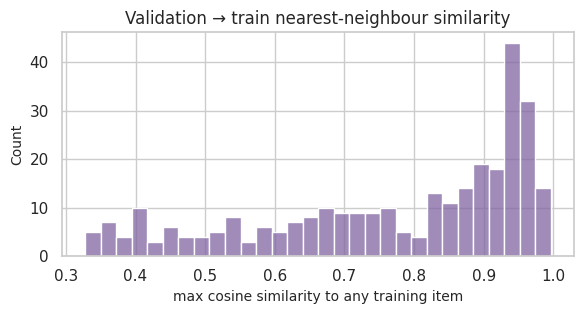

In [20]:
# ---- remaining near-duplicate / shared-template overlap (quantified, nothing removed) --------
sig_tr = set(train.iloc[idx_tr]["_sig"]); sig_va = train.iloc[idx_va]["_sig"]
share_template_in_train = float(sig_va.isin(sig_tr).mean())

vec_tr = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit(train.iloc[idx_tr]["_norm"])
Xt, Xv = vec_tr.transform(train.iloc[idx_tr]["_norm"]), vec_tr.transform(train.iloc[idx_va]["_norm"])
max_sim = np.asarray((Xv @ Xt.T).max(axis=1).todense()).ravel()
leak = pd.Series({"validation items sharing a template with a training item (%)": round(100 * share_template_in_train, 1),
                  "validation items with max TF-IDF sim >= 0.8 to a training item (%)": round(100 * (max_sim >= 0.8).mean(), 1),
                  "... >= 0.9 (%)": round(100 * (max_sim >= 0.9).mean(), 1),
                  "... >= 0.95 (%)": round(100 * (max_sim >= 0.95).mean(), 1),
                  "median max-similarity": round(float(np.median(max_sim)), 3)}).to_frame("value")
display(leak)
save_table(leak, "split_leakage_overlap")

fig, ax = plt.subplots(figsize=(6, 3.3))
sns.histplot(max_sim, bins=30, ax=ax, color="#8064a2"); ax.set_xlabel("max cosine similarity to any training item")
ax.set_title("Validation → train nearest-neighbour similarity")
plt.tight_layout(); plt.show()

In [21]:
# ---- save split files (originals are never touched) ----------------------------------
manifest = pd.concat([pd.DataFrame({"id": train_split["id"], "split": "train"}),
                      pd.DataFrame({"id": val_split["id"], "split": "validation"})], ignore_index=True)
manifest_path = OUT_DIR / "split_manifest.csv"
if manifest_path.exists():
    old = pd.read_csv(manifest_path, dtype=str)
    same = old.sort_values("id").reset_index(drop=True).equals(manifest.sort_values("id").reset_index(drop=True))
    print("Existing manifest identical to the new split:", same)
    if not same: print("WARNING: a different split existed before — make sure all experiments use ONE split.")

train_split.to_csv(OUT_DIR / "train_split.csv", index=False, encoding="utf-8")
val_split.to_csv(OUT_DIR / "validation_split.csv", index=False, encoding="utf-8")
manifest.to_csv(manifest_path, index=False, encoding="utf-8")
print("Saved:", [p.name for p in (OUT_DIR / "train_split.csv", OUT_DIR / "validation_split.csv", manifest_path)])
print("Reload with pd.read_csv(..., dtype=str) to preserve id/answer formatting.")

Saved: ['train_split.csv', 'validation_split.csv', 'split_manifest.csv']
Reload with pd.read_csv(..., dtype=str) to preserve id/answer formatting.


## 11. Summary tables (all values computed above)

In [22]:
cov = lambda col: round(100 * ann[col].mean(), 1)
summary = pd.DataFrame([
    ("Dataset sizes", "train / test / sample_submission rows", f"{len(train)} / {len(test)} / {len(sample_sub)}"),
    ("Dataset sizes", "train split / validation split", f"{len(train_split)} / {len(val_split)}"),
    ("Skills", "number of skills (train / test)", f"{train['skill'].nunique()} / {test['skill'].nunique()}"),
    ("Skill distribution", "min / median / mean / max per skill", " / ".join(str(skill_stats[k]) for k in ["min", "median", "mean", "max"])),
    *[("Answer types", f"% {t}", f"{type_tbl.loc[t, 'pct']}") for t in type_tbl.index],
    ("Annotation coverage", "% problems with non-empty steps", cov("has_steps")),
    ("Annotation coverage", "% problems with hints", cov("has_hints")),
    ("Annotation coverage", "% problems with typical errors", cov("has_errors")),
    ("Duplicates / templates", "normalized duplicate rows", dup_stats["norm_dup_rows"]),
    ("Duplicates / templates", "duplicate groups with conflicting answers", dup_stats["norm_dup_conflict_groups"]),
    ("Duplicates / templates", "% problems in a shared template", dup_stats["pct_in_shared_template"]),
    ("Duplicates / templates", "near-duplicate pairs (sim >= 0.9)", dup_stats["near_pairs_ge_0.9"]),
    ("Split", "% validation items sharing a template with train", round(100 * share_template_in_train, 1)),
], columns=["area", "metric", "value"])
display(summary)
summary.to_csv(TABLE_DIR / "eda_summary.csv", index=False, encoding="utf-8")

# Potential data-quality issues, derived from the checks above.
issues = []
def flag(cond, msg):
    if cond: issues.append(msg)
flag(miss_df.loc[miss_df.dataset == "train", ["missing", "whitespace_only"]].sum().sum() > 0, "train has missing/blank cells (see section 2; steps/hints/typical_errors may legitimately be empty)")
flag(integrity.loc["train duplicated ids", "value"] > 0, "duplicate ids in train")
flag(integrity.loc["train ∩ test ids", "value"] > 0, "ids overlap between train and test")
flag(not integrity.loc["test ids == sample_submission ids (as sets)", "value"], "test ids differ from sample_submission ids")
flag(len(issue_counts) > 0, f"non-canonical answer formats: {dict(issue_counts)}")
flag(dup_stats["norm_dup_conflict_groups"] > 0, "duplicate statements with conflicting answers")
flag(dup_stats["norm_dup_rows"] > 0, "duplicate statements in train (kept together in the split)")
flag(len(wf) > 0 and int(wf["same_string_as_correct"].sum()) > 0, "typical-error entries identical to the correct answer")
flag(int((ann[["steps_status", "hints_status", "err_status"]] == "parse_error").sum().sum()) > 0, "unparseable steps/hints/typical_errors cells")
flag(n_unextractable > 0, "typical-error entries without an extractable answer value")
print("Potential data-quality issues:" if issues else "No data-quality issues detected by the automated checks.")
for m in issues: print(" -", m)

,area,metric,value
0,Dataset sizes,train / test / sample_submission rows,1526 / 3561 / 3561
1,Dataset sizes,train split / validation split,1220 / 306
2,Skills,number of skills (train / test),29 / 29
3,Skill distribution,min / median / mean / max per skill,15.0 / 58.0 / 52.62 / 60.0
4,Answer types,% Integer,89.52
5,Answer types,% Decimal,8.91
6,Answer types,% Fraction,1.57
7,Annotation coverage,% problems with non-empty steps,47.7
8,Annotation coverage,% problems with hints,100.0
9,Annotation coverage,% problems with typical errors,100.0


No data-quality issues detected by the automated checks.


## 12. Planning: from observations to experiments
**Observed (see computed tables above):** skill sizes and per-skill answer-type mix; answer-format variety and any non-canonical answers; statement length/number-count proxies per skill; annotation coverage for `steps`, `hints`, `typical_errors`; duplicate, near-duplicate and shared-template rates; the fixed split and its residual template overlap.

**Hypotheses (nothing below has been evaluated; none is assumed to improve accuracy):**

| Experiment | Hypothesis motivated by the EDA | How to test on the fixed validation split |
|---|---|---|
| Skill-aware few-shot | Skills with a dominant, fixed answer format may benefit from demonstrations of that format; examples come from the **train split** only | Compare zero-shot vs. k-shot accuracy, overall and per skill, with answer-format error counted separately |
| Structured CoT | Problems with many intermediate values/long statements may gain more from step-by-step reasoning | Accuracy vs. proxy complexity buckets (intermediate-value count is available only for training problems → bucket by statement length / numeric-expression count for validation) |
| Calculator / Python tool use (model-generated) | Arithmetic errors with decimals and fractions may dominate; formatting to the canonical representation must still be handled | Compare with and without tool use; keep a per-type error breakdown |
| LoRA SFT | Enough training items per skill for light fine-tuning; shared templates may help (and may inflate validation) | Train on train split only; report validation accuracy next to the template-overlap figures above |
| DPO with typical wrong answers | Annotated wrong answers could define *rejected final answers*, but full rejected reasoning traces must be produced separately | Build pairs from train-split problems only; evaluate on validation |
| Synthetic data (allowed open model or an independent generator) | Rare skills/templates could be augmented | Verify any generated solution against train-split canonical answers; never use validation problems |

**Guard-rails for every later notebook:** load `split_manifest.csv`; never expose validation answers/hints/steps/typical errors to training, teacher generation or prompts; do not inspect test problems to choose strategies; keep proprietary LLMs out of labeling, generating or solving dataset problems.